## Exploración de datos (EDA)

Antes de usar cualquier modelo, conviene conocer el dataset: qué contiene, si está limpio y si los ratings realmente promedian ~4.5 estrellas.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", None)

# El notebook vive en src/; los datos, en la raíz del proyecto
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "reviews.csv"

df = pd.read_csv(RAW_PATH)
print(f"Forma: {df.shape[0]} filas x {df.shape[1]} columnas")
df.info()

Forma: 500 filas x 3 columnas
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    500 non-null    int64
 1   rating       500 non-null    int64
 2   review_text  500 non-null    str  
dtypes: int64(2), str(1)
memory usage: 11.8 KB


In [2]:
df.head()

,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


Tres columnas, tipos correctos y 500 reseñas, tal como anticipó la account manager. Veamos la calidad: faltantes y duplicados.

In [3]:
print("Valores faltantes por columna:")
print(df.isna().sum().to_string())
print(f"\nIDs duplicados: {df['review_id'].duplicated().sum()}")
print(f"Textos vacíos o solo espacios: {(df['review_text'].str.strip() == '').sum()}")
print(f"Textos duplicados (mismo texto, distinto review_id): {df['review_text'].duplicated().sum()}")

Valores faltantes por columna:
review_id      0
rating         0
review_text    0

IDs duplicados: 0
Textos vacíos o solo espacios: 0
Textos duplicados (mismo texto, distinto review_id): 7


In [4]:
# ¿Los textos duplicados también comparten rating?
dups = df[df["review_text"].duplicated(keep=False)].sort_values("review_text")
dups.groupby("review_text").agg(review_ids=("review_id", list), ratings=("rating", list))

,review_ids,ratings
review_text,,
"Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes just to get water, but overall a solid experience. Will definitely be back!","[51, 113]","[4, 4]"
Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.,"[177, 195]","[2, 2]"
Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.,"[292, 484]","[5, 5]"
Grabbed a quick coffee at Harbor House Café this morning. The sourdough bread alone is worth the visit. The team clearly cares about the customers. Will definitely be back!,"[41, 108]","[5, 5]"
"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. Might give it another shot.","[110, 451]","[3, 3]"
"Tried Harbor House Café after seeing it recommended online. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop.","[313, 345]","[3, 3]"
"Tried Harbor House Café after seeing it recommended online. The place has such a cozy, welcoming vibe. Service was fast and friendly. This is now my go-to spot.","[65, 449]","[5, 5]"


No hay faltantes ni IDs repetidos. Hay 7 pares de textos idénticos con distinto `review_id` y **el mismo rating**, así que no se contradicen. Pasemos a la variable clave: el rating.

In [5]:
rating_counts = df["rating"].value_counts().sort_index()
rating_pct = (rating_counts / len(df) * 100).round(1)
display(pd.DataFrame({"reseñas": rating_counts, "%": rating_pct}))
print(f"Rating promedio: {df['rating'].mean():.2f}  |  mediana: {df['rating'].median():.0f}")

,reseñas,%
rating,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


Rating promedio: 4.50  |  mediana: 5


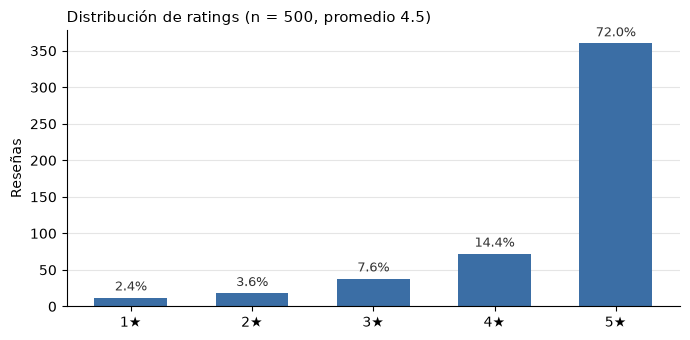

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(rating_counts.index, rating_counts.values, width=0.6, color="#3b6ea5")
ax.bar_label(bars, labels=[f"{p}%" for p in rating_pct], padding=3, fontsize=9, color="#333")
ax.set_xticks(rating_counts.index, [f"{r}★" for r in rating_counts.index])
ax.set_ylabel("Reseñas")
ax.set_title("Distribución de ratings (n = 500, promedio 4.5)", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

El promedio es exactamente **4.5** y la distribución está muy sesgada hacia las 5★. Para comparar después con el modelo, agrupamos los ratings humanos con el mismo mapeo que usaremos para las predicciones (1–2 Negativo, 3 Neutral, 4–5 Positivo).

In [7]:
def stars_to_band(stars: int) -> str:
    if stars <= 2:
        return "Negativo"
    if stars == 3:
        return "Neutral"
    return "Positivo"


human_band = df["rating"].map(stars_to_band)
(human_band.value_counts(normalize=True) * 100).round(1).reindex(["Positivo", "Neutral", "Negativo"]).to_frame("% según rating humano")

,% según rating humano
rating,
Positivo,86.4
Neutral,7.6
Negativo,6.0


Esa es la referencia: si el texto "coincidiera" perfectamente con las estrellas, el modelo debería acercarse a **86% positivo / 8% neutral / 6% negativo**. Ahora miremos el texto: longitud y contenido.

In [8]:
lengths = pd.DataFrame({
    "caracteres": df["review_text"].str.len(),
    "palabras": df["review_text"].str.split().str.len(),
})
display(lengths.describe().round(1).T)
display(lengths.assign(rating=df["rating"]).groupby("rating")["palabras"].mean().round(1).to_frame("palabras promedio"))

,count,mean,std,min,25%,50%,75%,max
caracteres,500.0,170.2,27.1,86.0,155.0,173.0,189.0,230.0
palabras,500.0,29.1,4.8,14.0,26.0,29.0,32.0,42.0


,palabras promedio
rating,
1,30.2
2,26.4
3,26.8
4,30.5
5,29.2


Reseñas cortas (14–42 palabras), muy por debajo del límite de 512 tokens de BERT, y sin diferencias de longitud relevantes entre ratings. Una pequeña muestra por rating para leerlas:

In [9]:
sample = df.groupby("rating", group_keys=False).sample(2, random_state=42)
sample[["review_id", "rating", "review_text"]]

,review_id,rating,review_text
441,442,1,Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.
427,428,1,Regular customer at Harbor House Café here. The coffee tasted burnt. The staff seemed annoyed to be there. It was way too loud to hold a conversation. Disappointing experience overall.
194,195,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
338,339,2,Regular customer at Harbor House Café here. The coffee tasted burnt. Nobody checked on us the entire meal. Disappointing experience overall.
479,480,3,"Visited Harbor House Café last weekend. Average sandwiches, nothing to write home about. The staff seemed annoyed to be there. Might give it another shot."
161,162,3,"Visited Harbor House Café last weekend. The menu is fine but a bit repetitive. Service was fine, nothing memorable. It's fine for a quick stop."
323,324,4,"Came to Harbor House Café for a birthday brunch. The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. It's fine for a quick stop."
20,21,4,"The coffee was rich and perfectly brewed. The staff were polite but a bit slow, but overall a solid experience. This is now my go-to spot."
143,144,5,The music and decor set the perfect mood. Best brunch i've had in months. Five stars without hesitation.
136,137,5,Grabbed a quick coffee at Harbor House Café this morning. Great spot to work or catch up with friends. The team clearly cares about the customers. Five stars without hesitation.


Las reseñas parecen seguir una plantilla: una frase de apertura, una o dos sobre comida/servicio/ambiente y un cierre. Lo comprobamos partiendo cada reseña en frases.

In [10]:
sentences = (
    df.assign(sentence=df["review_text"].str.split(r"(?<=[.!?])\s+"))
      .explode("sentence")
)
sentences = sentences[sentences["sentence"].str.strip() != ""]
print(f"Frases totales: {len(sentences)}  |  frases únicas: {sentences['sentence'].nunique()}")

openings = df["review_text"].str.split(".").str[0]
print(f"Aperturas únicas: {openings.nunique()} (las 6 más comunes cubren {openings.value_counts().head(6).sum()} reseñas)")

Frases totales: 2108  |  frases únicas: 69
Aperturas únicas: 28 (las 6 más comunes cubren 433 reseñas)


Solo **69 frases únicas** en 2 108: el dataset se construyó combinando frases de un repertorio fijo. Lo que más importa para el análisis de sentimiento es que algunas reseñas mezclan una **queja de servicio** con un giro positivo al final.

In [11]:
MIXED_PATTERNS = {
    "queja + 'but overall a solid experience'": "but overall a solid experience",
    "queja + 'but honestly the food made up for it'": "but honestly the food made up for it",
}
mixed = pd.DataFrame({name: df["review_text"].str.contains(pat, regex=False)
                      for name, pat in MIXED_PATTERNS.items()})
mixed_by_rating = mixed.groupby(df["rating"]).sum()
mixed_by_rating.loc["total"] = mixed_by_rating.sum()
mixed_by_rating

,queja + 'but overall a solid experience',queja + 'but honestly the food made up for it'
rating,,
1,0,0
2,0,0
3,0,0
4,69,0
5,0,21
total,69,21


In [12]:
df[mixed.any(axis=1)].groupby("rating").head(2)[["review_id", "rating", "review_text"]]

,review_id,rating,review_text
9,10,5,"The pastries were incredible. The staff seemed annoyed to be there, but honestly the food made up for it. This is now my go-to spot."
16,17,4,"Tried Harbor House Café after seeing it recommended online. The sourdough bread alone is worth the visit. The staff were polite but a bit slow, but overall a solid experience. Five stars without hesitation."
18,19,4,"Regular customer at Harbor House Café here. The pastries were incredible. The staff were polite but a bit slow, but overall a solid experience. Might give it another shot."
21,22,5,"Fresh ingredients you can really taste. We waited 25 minutes just to get water, but honestly the food made up for it. Will definitely be back!"


**90 reseñas (18%)** son de 4–5★ pero contienen una queja concreta (esperas, personal molesto, pedidos equivocados). Para un modelo entrenado con reseñas de productos, son las candidatas naturales a **falsos negativos**.

Por último, ¿hay frases que aparecen en reseñas de **bandas** distintas (p. ej. una queja en una reseña de 3★)?

In [13]:
sent_stats = sentences.groupby("sentence")["rating"].agg(["count", "min", "max", "mean"]).round(2)
crosses_band = sent_stats["min"].map(stars_to_band) != sent_stats["max"].map(stars_to_band)
# Excluimos las aperturas neutras ("Visited Harbor House Café...") que aparecen con cualquier rating
inconsistent = sent_stats[crosses_band & ~sent_stats.index.str.contains("Harbor House")]
inconsistent.sort_values("mean")

,count,min,max,mean
sentence,,,,
The cashier was rude when i asked about the menu.,6,1,3,1.67
Nobody checked on us the entire meal.,10,1,3,1.90
Our server got our order wrong twice.,10,1,3,2.10
The staff seemed annoyed to be there.,5,1,3,2.20
"The food was decent, nothing special.",8,2,3,2.88
"Service was fine, nothing memorable.",10,2,3,2.90
The menu is fine but a bit repetitive.,11,2,3,2.91
The staff were polite but a bit slow.,15,2,3,2.93
Might give it another shot.,23,3,4,3.30


### Insights clave

1. **El promedio de 4.5★ es real**: 86% de las reseñas son de 4–5★, 8% de 3★ y 6% de 1–2★. Es la línea base contra la que compararemos el modelo.
2. **El texto es corto y limpio**: sin faltantes ni textos vacíos, y con longitudes muy por debajo del límite de BERT; no hace falta truncar ni preprocesar.
3. **El dataset es de plantilla** (69 frases únicas): los errores del modelo se repetirán en bloque, así que será fácil encontrar *patrones* de falsos negativos, no solo casos sueltos.
4. **18% de las reseñas son mixtas**: queja de servicio + cierre positivo, y aun así 4–5★. Es el punto más probable de desacuerdo entre texto y estrellas.
5. **Hay ruido en las fronteras del rating humano**: quejas como "The cashier was rude" en reseñas de 3★ y cierres tibios ("Might give it another shot") en reseñas de 4★. Algunas "discrepancias" vendrán del rating, no del modelo.

### Propuesta de limpieza

**No se necesita limpieza.** No hay faltantes, tipos incorrectos ni textos vacíos, y el modelo es *uncased*, así que no importan mayúsculas ni detalles como "i" en minúscula.

- **Duplicados (7 pares)**: se **conservan**. Tienen `review_id` distinto y el mismo rating, y el cliente entregará las 500 reseñas como un conjunto; eliminarlos cambiaría la base sobre la que se calcula el 4.5★ (y movería los porcentajes ~1 punto como máximo).
- **Texto**: se pasa al modelo tal cual. Quitar puntuación o *stopwords* le restaría contexto que el modelo sí sabe usar.